# Import

In [1]:

from sklearn.metrics import accuracy_score, f1_score,classification_report, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import shap 
from sklearn.model_selection import GridSearchCV
from catboost import CatBoostClassifier
import pandas as pd
import os
import shap
from pathlib import Path
from sklearn.model_selection import train_test_split
import pandas as pd
import os
import shap
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report,ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier


c:\Users\dkuch\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
os.environ["KERAS_BACKEND"] = "torch"
import keras
from keras.models import Sequential
from keras.layers import Dense




In [3]:

def removeNan(ox):
  
    ox['maxspeedReady'] = ox['maxRychlostOSM'].apply(getOsmMaxSpeedMedian)

    #rychlost
    ox['maxRychlostTomTom'] = ox['maxRychlostTomTom'].fillna(ox['maxspeedReady'])

    #podle cisla komunikace
    ox['maxRychlostTomTom'] =ox['maxRychlostTomTom'].fillna(
        ox.groupby(["cisloKomunikace", "druhKomunikace",'umisteniObec'])['maxRychlostTomTom'].transform('median')
    )


    ox['maxRychlostTomTom'] =ox['maxRychlostTomTom'].fillna(
        ox.groupby(["druhKomunikace", 'umisteniObec'])['maxRychlostTomTom'].transform('median')
    )

    #hustota
    ox['pocetSondTomTom'] = ox['pocetSondTomTom'].fillna(
        ox.groupby(["umisteniObec","usekStartOSM", "usekKonecOSM","cisloKomunikace","druhKomunikace","den","hodina"])['pocetSondTomTom'].transform('median')
    )

    ox['pocetSondTomTom'] = ox['pocetSondTomTom'].fillna(
        ox.groupby(["umisteniObec","usekStartOSM", "usekKonecOSM","druhKomunikace","den","hodina"])['pocetSondTomTom'].transform('median')
    )

    ox['pocetSondTomTom'] = ox['pocetSondTomTom'].fillna(
        ox.groupby(["umisteniObec","usekStartOSM", "usekKonecOSM","den","hodina"])['pocetSondTomTom'].transform('median')
    )

    ox['pocetSondTomTom'] = ox['pocetSondTomTom'].fillna(
        ox.groupby(["umisteniObec","cisloKomunikace", "druhKomunikace","den","hodina"])['pocetSondTomTom'].transform('median')
    )

    ox['pocetSondTomTom'] = ox['pocetSondTomTom'].fillna(
        ox.groupby(["den","hodina", "druhKomunikace","deleniKomunikace","hodina"])['pocetSondTomTom'].transform('median')
    )

    ox['pocetSondTomTom'] = ox['pocetSondTomTom'].fillna(
        ox.groupby(["cisloKomunikace","deleniKomunikace","den","hodina",])['pocetSondTomTom'].transform('median')
    )


    ox['sinuositaOSM'] = ox['sinuositaOSM'].fillna(
        ox.groupby(["cisloKomunikace","deleniKomunikace"])['sinuositaOSM'].transform('median')
    )

    ox['delkaUsekuOSM'] = ox['delkaUsekuOSM'].fillna(
        ox.groupby(["cisloKomunikace","deleniKomunikace"])['delkaUsekuOSM'].transform('median')
    )    

    return ox

def getMode(x):
    m = x.mode()
    return m.iloc[0] if not m.empty else None

import ast

def getOsmMaxSpeedMedian(osmSpeed):  
    if pd.isna(osmSpeed) or osmSpeed == '':
        return np.nan
    
  
    if isinstance(osmSpeed, (int, float)):
        return float(osmSpeed)
    
  
    if isinstance(osmSpeed, str) and osmSpeed.startswith('['):
        try:
           
            speedList = ast.literal_eval(osmSpeed)
           
            return np.median([float(i) for i in speedList])
        except (ValueError, SyntaxError):
            return np.nan
            
 
    try:
        return float(osmSpeed)
    except ValueError:
        return np.nan


def selectCols(df):
    return df[cols]

def encodeLabels(df):
    global categorical_dims,categoricalCols,features
    newDf=df
    le=LabelEncoder()
    categorical_dims = {}
    categoricalCols=da.getObjectColumnsNames(newDf)
    features = [col for col in df.columns if col != label]

    for col in da.getObjectColumnsNames(newDf):
        newDf[col]=le.fit_transform(newDf[col].values)
        categorical_dims[col]=len(le.classes_)
        
        
    return newDf
        
def aggregateFeatureImportance(originalCols,encodedCols,fi):    

    aggregated_importances = {feat: 0 for feat in originalCols}


    for name, importance in zip(encodedCols,fi):
        for orig in originalCols:
            if orig in name: 
                aggregated_importances[orig] += importance
                break


    feat_imp_df = pd.Series(aggregated_importances).sort_values(ascending=False)
    feat_imp_df.plot(kind='bar', color='teal')
    plt.title("Důležitost původních příznaků")
    plt.ylabel("Agregovaná důležitost")
    plt.show()

    return aggregated_importances

def getColumnFeatureImportance(df,fiDf,colName):
    
    oeCols= [col for col in df[colName] if col.startswith(colName)]
    df[df["colNames"].isin(oeCols)].sort_values('importance',ascending=False)
#originalY["zavaznostNehody"]=lb.fit_transform(originalY["zavaznostNehody"])

def getFiDf(trainDf,fi):
    return pd.DataFrame({"colNames":trainDf.columns,"importance":fi}).sort_values('importance',ascending=False)

def getTransformedlDf(pip,df):
    pip.set_output(transform="pandas")
    return pip.named_steps['prep'].transform(df)

from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from category_encoders import TargetEncoder

def setToCategories(df,catCols):
    for col in catCols:
        df[col] = df[col].astype('category')

    return df

def agregateHours(df,columnName):
    intervals=[]
    intervals.append((5,9,"rano"))
    intervals.append((10,12,"dopoledne"))
    intervals.append((13,17,"odpoledne"))
    intervals.append((18,20,"vecer"))
    intervals.append((21,23,"noc"))
    intervals.append((0,4,"noc"))

    nDF=pd.DataFrame()
    rDF=pd.DataFrame()

    for interval in intervals:
        nDF=pd.concat([nDF,df[(df[columnName]>=interval[0]) & (df[columnName]<=interval[1])]])
    
        nDF[columnName]=interval[2]
        rDF=pd.concat([nDF,rDF])
        nDF=pd.DataFrame()

    nDf=df[df.hodina.isnull()]
    nDf["hodina"]="neznamo"
    
    rDF=pd.concat([rDF,nDf])

    return rDF

def updateWeather(df):
    df['teplotaApi'][df.hodina=="neznamo"] = df['teplotaPrumApi'][df.hodina=="neznamo"]
    df['srazkyApi'][df.hodina=="neznamo"] = df['srazkyPrumApi'][df.hodina=="neznamo"]
    df['snehovaPokryvkaApi'][df.hodina=="neznamo"] = df['snehovaPokryvkaPrumApi'][df.hodina=="neznamo"]

    return df

def displayFI(model, featureNames, title="Feature Importance", topAttr=30):
  
    importances = model.feature_importances_   

    featImp = pd.DataFrame({
        "Attribute": featureNames,
        "Importance": importances
    })
    
    featImp = featImp.sort_values(by="Importance", ascending=False).head(topAttr)

    plt.figure(figsize=(12, 8))
    
  
    sns.barplot(
        x='Importance', 
        y='Attribute', 
        data=featImp, 
        palette='viridis',
        hue='Attribute',
        legend=False
    )
    
    sns.despine()
    plt.title(f'{title} (TOP {topAttr})', fontsize=14)
    plt.xlabel('Score')
    plt.ylabel('')
    plt.tight_layout()

    plt.show()


In [4]:
def createGridSearch(estimator,gridParams,folds,score):
    return GridSearchCV(
    estimator=estimator, 
    param_grid=gridParams, 
    cv=folds, 
    scoring=score,
    verbose=2, 
    n_jobs=-1
    )
    

def getBinaryCM(estimator, threshold,xTest,yTest):
    yProb=estimator.predict_proba(xTest)[:, 1]
    threshold=0.5
    yPred = (yProb >= threshold).astype(int)

    cm = confusion_matrix(yTest, yPred)

    plt.figure(figsize=(8, 6))
    dispCM = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Nehoda bez zranění', 'Nehoda se zraněním'])
    dispCM.plot(cmap='viridis', values_format='d') 

    plt.grid(False)
    plt.show()


    
    print(classification_report(yTest,yPred))

def displayCodedCat(df,catName):
    mapping = dict(enumerate(df[catName].cat.categories))
    for c, n in mapping.items():        
        print(f"  {c} = {n}")

def getValuesByShapThreshold(xTest,targetCol,threshold,shapValues,originalDf):  
    xTestIndexes = xTest.columns.get_loc(targetCol)

    currentShap = shapValues[:, xTestIndexes]
    condition = currentShap > threshold


    shapIndexes = xTest[condition].index
    resultDf = originalDf.loc[shapIndexes].copy()
    resultDf['shapValue'] = currentShap[condition]

    resultDf = resultDf.sort_values(by='shapValue', ascending=False)

    return resultDf

def getShapValues(estimator,xTest):
    explainer = shap.TreeExplainer(estimator)
    shapValues = explainer.shap_values(xTest)

    return shapValues
def getExplanation(estimator,xTest): 
    explainer = shap.TreeExplainer(estimator)
    return explainer(xTest)

def displayLocalValues(explanation,index,maxDisplay):
    shap.plots.waterfall(explanation[index],max_display=maxDisplay)

def displaySummaryPlot(shapValues,xTest,maxCols,catCols,title=""):
    plt.figure(figsize=(10, 8))

    xTestCopy = xTest.copy()
    for col in catCols:   
        if xTestCopy[col].dtype.name == 'category':
            xTestCopy [col] = xTestCopy [col].cat.codes

    shap.summary_plot(shapValues, xTestCopy, max_display=maxCols, show=False)

    plt.title(title, fontsize=15)
    plt.tight_layout()
    plt.show()

def displayNumericSummaryPlot(shapValues,xTest,maxCols,title=""):
    plt.figure(figsize=(10, 8))   

    shap.summary_plot(shapValues, xTest, max_display=maxCols, show=False)

    plt.title(title, fontsize=15)
    plt.tight_layout()
    plt.show()

def displayDependencePlot(shapValues,xTest,col):
    shap.dependence_plot(col, shapValues, xTest, display_features=xTest)

def displayInteractionDependencePlot(shapValues,xTest,col,interactionCol):
    shap.dependence_plot(col, shapValues, xTest, interaction_index=interactionCol)

def performTargetEncoding(xTrain,yTrain,xTest,col):
    encoder = TargetEncoder(cols=[col])
    #encoder = TargetEncoder(cols=[col], smoothing=10)
    xTrain[col] = encoder.fit_transform(xTrain[col], yTrain)
    xTest[col] = encoder.transform(xTest[col])


    xTrain[col] = xTrain[col].astype(float)
    xTest[col] = xTest[col].astype(float)

    return xTrain,xTest

def getCorrectIndexes(yPred,yTest):
    return np.where(yPred == yTest)[0]


In [5]:
dfAccidents = pd.read_csv("data.csv", sep=';')

C:\Users\dkuch\AppData\Local\Temp\ipykernel_7048\634222577.py:1: DtypeWarning: Columns (0: cisloKomunikace) have mixed types. Specify dtype option on import or set low_memory=False.
  dfAccidents = pd.read_csv("data.csv", sep=';')


In [6]:
from sklearn.feature_selection import mutual_info_classif

# Mutual Information

In [7]:
label="zavaznostNehody"

numCols = [
     "teplotaMaxApi","srazkyMaxApi","snehovaPokryvkaMaxApi",
    "teplotaPrumApi","srazkyPrumApi","snehovaPokryvkaPrumApi",
    "teplotaApi","srazkyApi","snehovaPokryvkaApi"
]

df=dfAccidents.copy()

df=df[numCols+[label]]
df=df.dropna()

In [9]:
X = df[numCols]
y = df[label]

miResults = mutual_info_classif(X, y,random_state=42)

resultDf = pd.DataFrame({
    'Atribut': numCols,
    'miScore': miResults
}).sort_values(by='miScore', ascending=False)

C:\Users\dkuch\AppData\Local\Temp\ipykernel_13276\3252506707.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=resultDf, x='miScore', y='Atribut', palette='viridis')


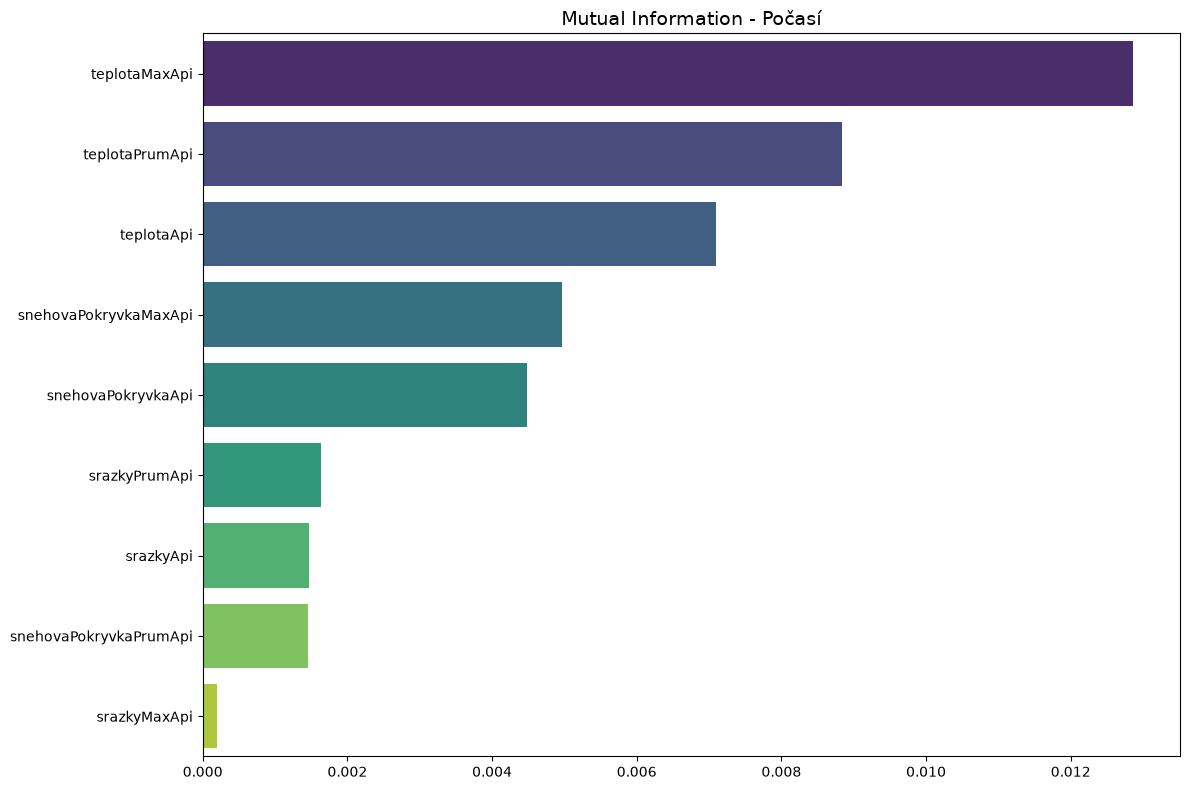

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(12, 8))
sns.barplot(data=resultDf, x='miScore', y='Atribut', palette='viridis')

plt.title('Mutual Information - Počasí', fontsize=14)
plt.xlabel('', fontsize=12)
plt.ylabel('')
plt.tight_layout()

plt.show()

In [11]:


label="zavaznostNehody"

catCols = ["hodina","umisteniObec", "rozhledovePodminky", "povrchVozovky", "povetrnostniPodminky", 
    "viditelnost", "specifikaceSmerovyPomer", "druhKomunikace", "den", 
    "typVozidla", "typSrazkyVozidlo", "typSrazkyPrekazka", "pricinaNehody", 
    "viditelnostDleCastiDne", "osvetleni", "mostOSM", "tunelOSM", "jednosmernaCestaOSM","mesic","alkohol"
]

numCols = [
     "pocetZucastnenychVozidel", "wgsX", "wgsY", "nadmorskaVyska", 
    "pocetSondTomTom", "maxRychlostTomTom" 
    , "delkaUsekuOSM", "sinuositaOSM","teplotaMaxApi","srazkyMaxApi","snehovaPokryvkaMaxApi"
]


df=dfAccidents.copy()

df=removeNan(df)
df=agregateHours(df,"hodina")

df=df[catCols+numCols+[label]]
df=df.dropna()


In [12]:

label='zavaznostNehody'

dfMut=df.copy()

X = dfMut[catCols+numCols]
y = dfMut[label]

for col in catCols:
    X[col] = X[col].astype('category').cat.codes
        
catIndexes = [X.columns.get_loc(col) for col in catCols]

miResults = mutual_info_classif(X, y, discrete_features=catIndexes,random_state=42)

resultDf = pd.DataFrame({
    'Atribut': catCols+numCols,
    'miScore': miResults
}).sort_values(by='miScore', ascending=False)


C:\Users\dkuch\AppData\Local\Temp\ipykernel_13276\2080613413.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=resultDf, x='miScore', y='Atribut', palette='viridis')


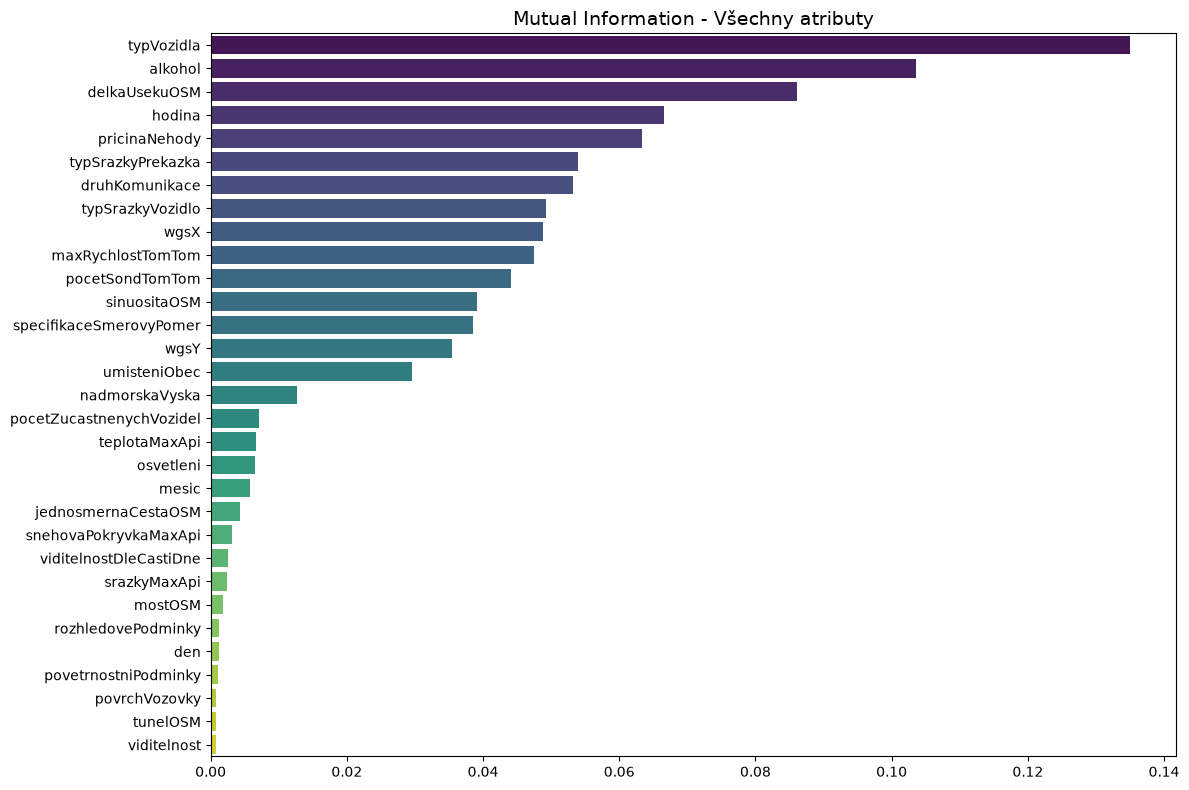

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.barplot(data=resultDf, x='miScore', y='Atribut', palette='viridis')

plt.title('Mutual Information - Všechny atributy', fontsize=14)
plt.xlabel('', fontsize=12)
plt.ylabel('')
plt.tight_layout()

plt.show()

# Grafy a predzpracovani

In [14]:


label="zavaznostNehody"

catCols = ["hodina","umisteniObec", "rozhledovePodminky", "povrchVozovky", "povetrnostniPodminky", 
    "viditelnost", "specifikaceSmerovyPomer", "druhKomunikace", "den", 
    "typVozidla", "typSrazkyVozidlo", "typSrazkyPrekazka", "pricinaNehody", 
    "viditelnostDleCastiDne", "osvetleni", "mostOSM", "tunelOSM", "jednosmernaCestaOSM","mesic","alkohol"
]

numCols = [
     "pocetZucastnenychVozidel", "wgsX", "wgsY", "nadmorskaVyska", 
    "pocetSondTomTom", "maxRychlostTomTom" 
    , "delkaUsekuOSM", "sinuositaOSM","teplotaMaxApi","srazkyMaxApi","snehovaPokryvkaMaxApi"
]

mixCol=["cluster25"]

df=dfAccidents.copy()

#df=df[(df.druhNehody=="srazkaVozidlo")]
#df=df[(df.druhNehody=="prekazka")]
#df=df[(df.druhNehody=="srazkaVozidlo") | (df.druhNehody=="prekazka")]

df=removeNan(df)
df=agregateHours(df,"hodina")

df=df[catCols+numCols+[label]+mixCol]
df=df.dropna()


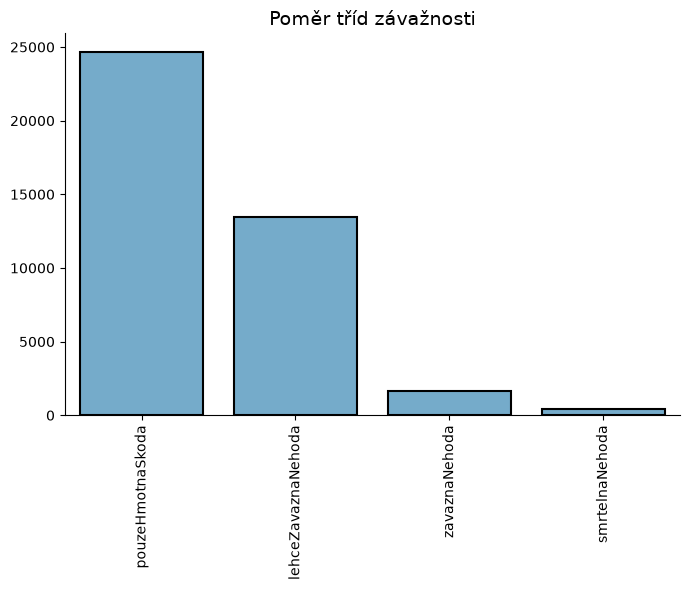

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

order= [
    'pouzeHmotnaSkoda',
    'lehceZavaznaNehoda',
    'zavaznaNehoda',
    'smrtelnaNehoda'
]

plt.figure(figsize=(7, 6))


sns.countplot(
    data=df, 
    x='zavaznostNehody', 
    color="#67afd8", 
    order=order,    
    edgecolor='black', 
    linewidth=1.5
)

plt.title('Poměr tříd závažnosti', fontsize=14)
plt.xlabel('')
plt.ylabel('')


plt.xticks(rotation=90)

sns.despine()

plt.tight_layout()
plt.show()

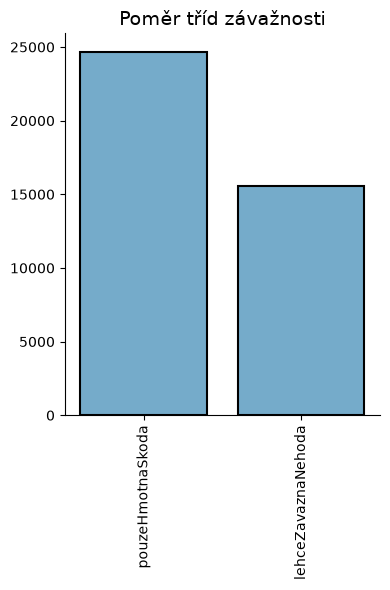

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
dfCopy=df.copy()

dfCopy.loc[dfCopy.zavaznostNehody=="zavaznaNehoda","zavaznostNehody"]="lehceZavaznaNehoda"
dfCopy.loc[dfCopy.zavaznostNehody=="smrtelnaNehoda","zavaznostNehody"]="lehceZavaznaNehoda"

order = [
    'pouzeHmotnaSkoda',
    'lehceZavaznaNehoda'
]

# Nastavení velikosti plátna
plt.figure(figsize=(4, 6))

# Vykreslení sloupcového grafu četností (sloupec 'zavaznostNehody' v DataFrame 'df')
# Pokud chcete přesně modré sloupce s černým ohraničením jako na obrázku:
sns.countplot(
    data=dfCopy, 
    x='zavaznostNehody', 
    color="#67afd8", 
    order=order,    
    edgecolor='black', 
    linewidth=1.5
)

# Úprava popisků a vzhledu
plt.title('Poměr tříd závažnosti', fontsize=14)
plt.xlabel('')
plt.ylabel('')

# Otočení popisků na ose X, aby se nepřekrývaly
plt.xticks(rotation=90)

# Odstranění horního a pravého rámečku grafu
sns.despine()

plt.tight_layout()
plt.show()

# XGB

In [8]:


label="zavaznostNehody"

catCols = ["hodina","umisteniObec", "rozhledovePodminky", "povrchVozovky", "povetrnostniPodminky", 
    "viditelnost", "specifikaceSmerovyPomer", "druhKomunikace", "den", 
    "typVozidla", "typSrazkyVozidlo", "typSrazkyPrekazka", "pricinaNehody", 
    "viditelnostDleCastiDne", "osvetleni", "mostOSM", "tunelOSM", "jednosmernaCestaOSM","mesic","alkohol"
]

numCols = [
     "pocetZucastnenychVozidel", "wgsX", "wgsY", "nadmorskaVyska", 
    "pocetSondTomTom", "maxRychlostTomTom" 
    , "delkaUsekuOSM", "sinuositaOSM","teplotaMaxApi","srazkyMaxApi","snehovaPokryvkaMaxApi"
]

mixCol=["cluster25"]

df=dfAccidents.copy()

#df=df[(df.druhNehody=="srazkaVozidlo")]
#df=df[(df.druhNehody=="prekazka")]
#df=df[(df.druhNehody=="srazkaVozidlo") | (df.druhNehody=="prekazka")]

df=removeNan(df)
df=agregateHours(df,"hodina")

df=df[catCols+numCols+[label]+mixCol]
df=df.dropna()


In [9]:
severityMapping = {
    'pouzeHmotnaSkoda': 0,
    'lehceZavaznaNehoda': 1,
    'zavaznaNehoda': 1,
    'smrtelnaNehoda': 1
}

y=df['zavaznostNehody'].map(severityMapping)
X = df[catCols + numCols+mixCol]

for col in catCols:
    X[col] =X[col].astype('category')


xTrain, xTest, yTrain, yTest = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

weights= compute_sample_weight(class_weight='balanced', y=yTrain)

xTrain,xTest=performTargetEncoding(xTrain,yTrain,xTest,"cluster25")


In [19]:
xTrain['jednosmernaCestaOSM'] = xTrain['jednosmernaCestaOSM'].astype(int)
xTest['jednosmernaCestaOSM'] = xTest['jednosmernaCestaOSM'].astype(int)

In [20]:
for col in xTrain.columns:
    if xTrain[col].dtype == 'bool' or xTrain[col].isin([True, False]).all():
        xTrain[col] = xTrain[col].astype(int)

In [21]:

xgbModel = XGBClassifier(
    objective='binary:logistic',
    enable_categorical=True,
    random_state=42
)

gridParams = {
    "n_estimators":[100,200,300,400,600],
    "max_depth":[3,6,8,10,12,14,16],
    "learning_rate":[0.05,0.1]
}

grid=createGridSearch(xgbModel,gridParams,3,'f1_macro')
grid.fit(xTrain, yTrain, sample_weight=weights)

print(f"\nparams: {grid.best_params_}")

bestEstimator = grid.best_estimator_
yPred = bestEstimator.predict(xTest)

Fitting 3 folds for each of 70 candidates, totalling 210 fits

params: {'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 200}


In [55]:
bestEstimator

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'count:poisson'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor

# CatBoost

In [12]:

cbModel = CatBoostClassifier(
    loss_function='Logloss',
    verbose=False,
    allow_writing_files=False,
    random_state=42
)

gridParams = {
    'iterations': [100,200,300,400,600],
    'depth': [4,6,8],
    'learning_rate': [0.05,0.1]
}

gridSearch =createGridSearch(cbModel,gridParams,3,'f1_macro')

gridSearch.fit(
    xTrain, yTrain, 
    cat_features=catCols,
    sample_weight=weights 
)

print(f"\nparams: {gridSearch.best_params_}")

bestEstimator = gridSearch.best_estimator_
yPred = bestEstimator.predict(xTest)

Fitting 3 folds for each of 30 candidates, totalling 90 fits

params: {'depth': 8, 'iterations': 400, 'learning_rate': 0.05}


In [13]:
bestEstimator

CatBoostClassifier(allow_writing_files=False, depth=8, iterations=400, learning_rate=0.05, loss_function='Logloss', random_state=42, verbose=False)

# Random Forest

In [ ]:

xTrain, xTest, yTrain, yTest = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

labelEncoder = LabelEncoder()

for col in catCols:   
    xTrain[col] = labelEncoder.fit_transform(xTrain[col])
    xTest[col] = labelEncoder.transform(xTest[col])

xTrain,xTest=performTargetEncoding(xTrain,yTrain,xTest,"cluster25")

In [37]:
rfModel = RandomForestClassifier(random_state=42)


gridParams = {
    "n_estimators": [100,200,300,400,600],
    "max_depth": [4,6,8]
}

gridSearch = GridSearchCV(
    estimator=rfModel, 
    param_grid=gridParams, 
    cv=3, 
    scoring="f1_macro",
    verbose=2, 
    n_jobs=-1
)

gridSearch.fit(xTrain, yTrain, sample_weight=weights)


print(f"\nparams: {gridSearch.best_params_}")

bestEstimator = gridSearch.best_estimator_
yPred = bestEstimator.predict(xTest)

Fitting 3 folds for each of 15 candidates, totalling 45 fits

params: {'max_depth': 8, 'n_estimators': 200}


# Confusion matrix

<Figure size 800x600 with 0 Axes>

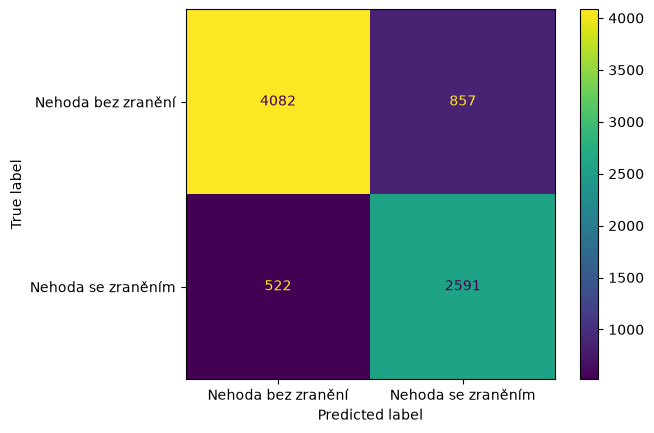

              precision    recall  f1-score   support

           0       0.89      0.83      0.86      4939
           1       0.75      0.83      0.79      3113

    accuracy                           0.83      8052
   macro avg       0.82      0.83      0.82      8052
weighted avg       0.83      0.83      0.83      8052



In [14]:
getBinaryCM(bestEstimator,0.5,xTest,yTest)

In [25]:
shapValues=getShapValues(bestEstimator,xTest)

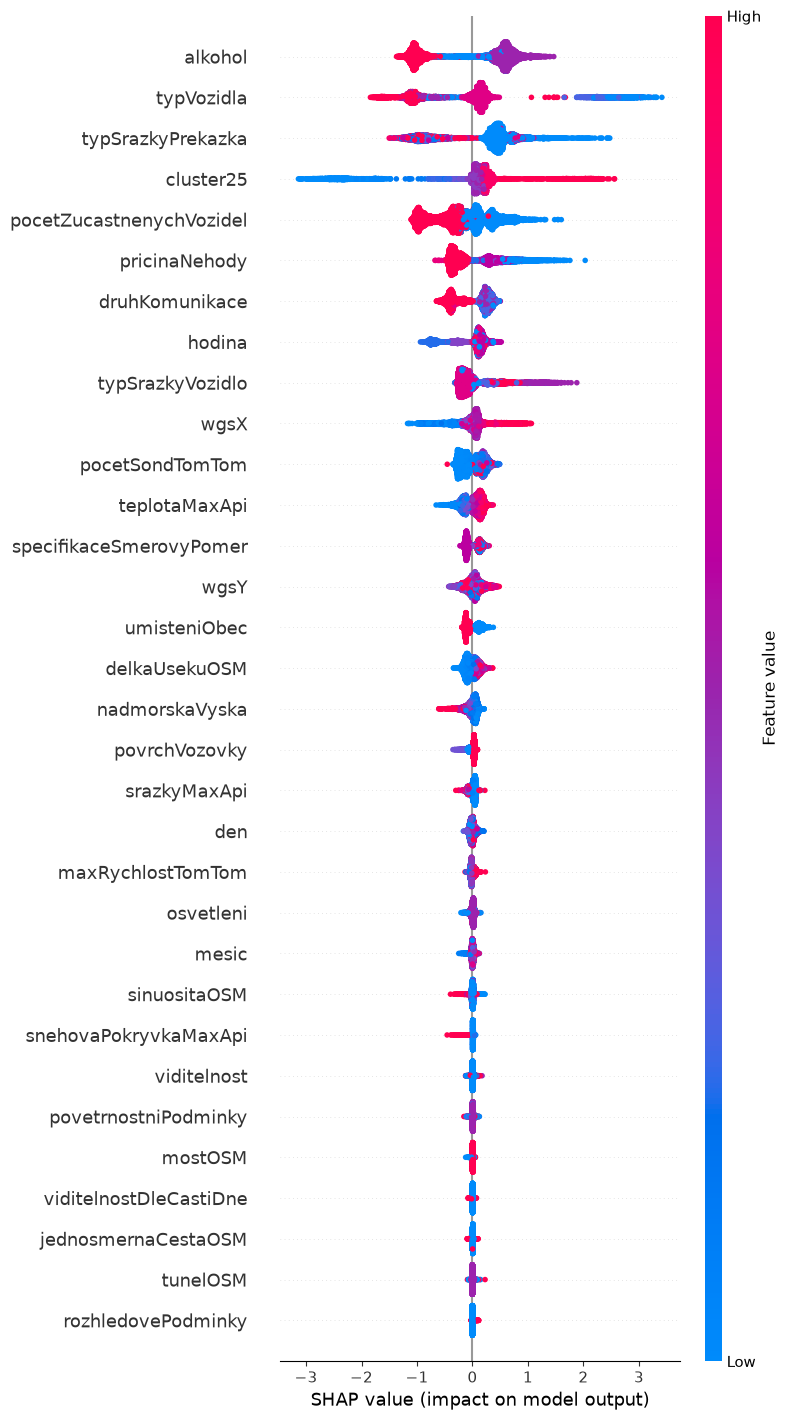

In [50]:
displaySummaryPlot(shapValues,xTest,40,catCols)

C:\Users\dkuch\AppData\Local\Temp\ipykernel_19804\3807240535.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


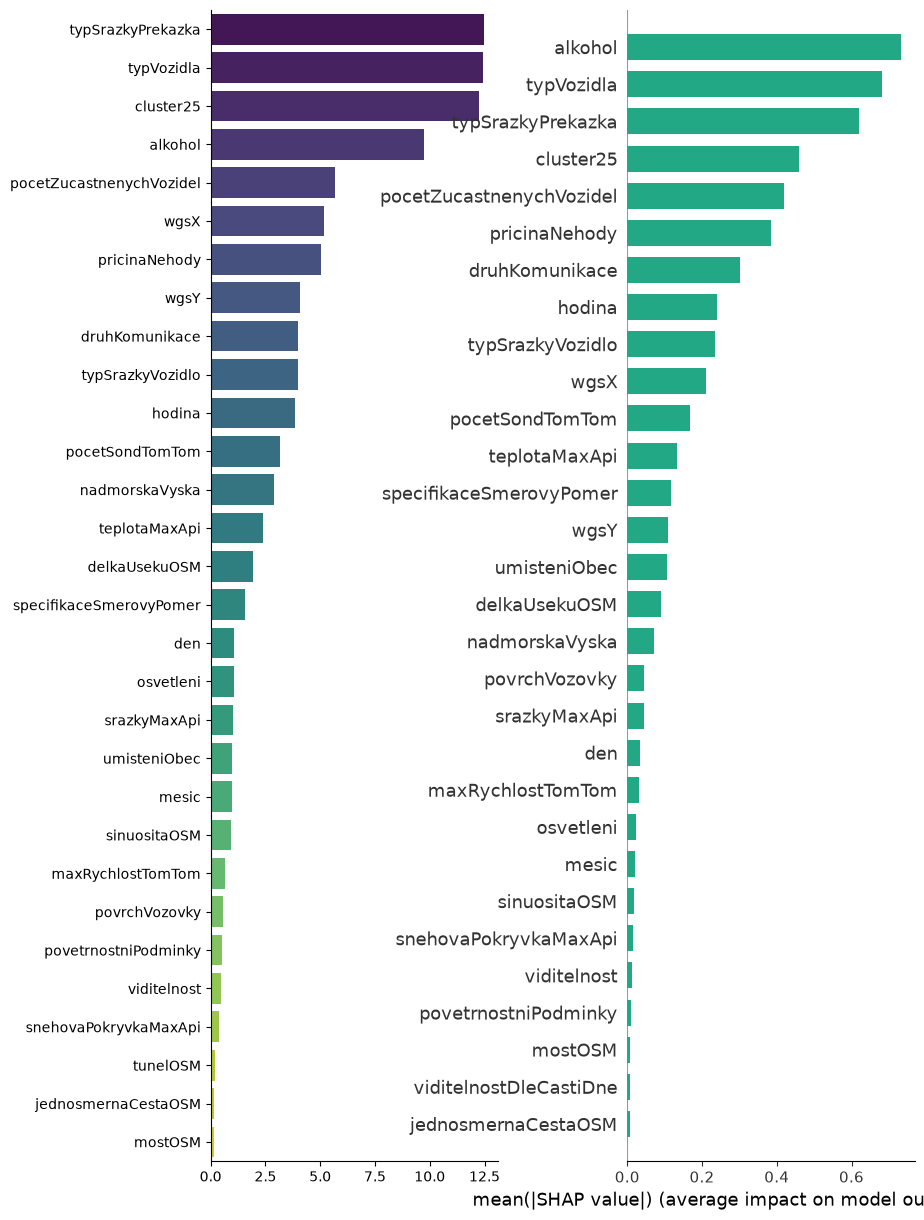

In [51]:
importances = bestEstimator.feature_importances_
attrNames = xTrain.columns


fi = pd.DataFrame({'Attribute': attrNames, 'Importance': importances})
fi = fi.sort_values(by='Importance', ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(38, 12), gridspec_kw={'width_ratios': [1, 1]})

sns.barplot(
    x='Importance', 
    y='Attribute', 
    data=fi.head(30), 
    palette='viridis', 
    ax=ax1
)
ax1.set_title('', fontsize=18, fontweight='bold', pad=20)
ax1.set_xlabel('', fontsize=14)
ax1.set_ylabel('', fontsize=14)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

plt.sca(ax2) 
shap.summary_plot(
    shapValues, 
    xTrain, 
    plot_type="bar", 
    color=plt.get_cmap("viridis")(0.6), 
    show=False,
    max_display=30
)
ax2.set_title("", fontsize=18, fontweight='bold', pad=20)
ax2.set_ylabel("")

plt.subplots_adjust(left=0.1, right=0.98, wspace=0.45, top=0.9)

plt.show()

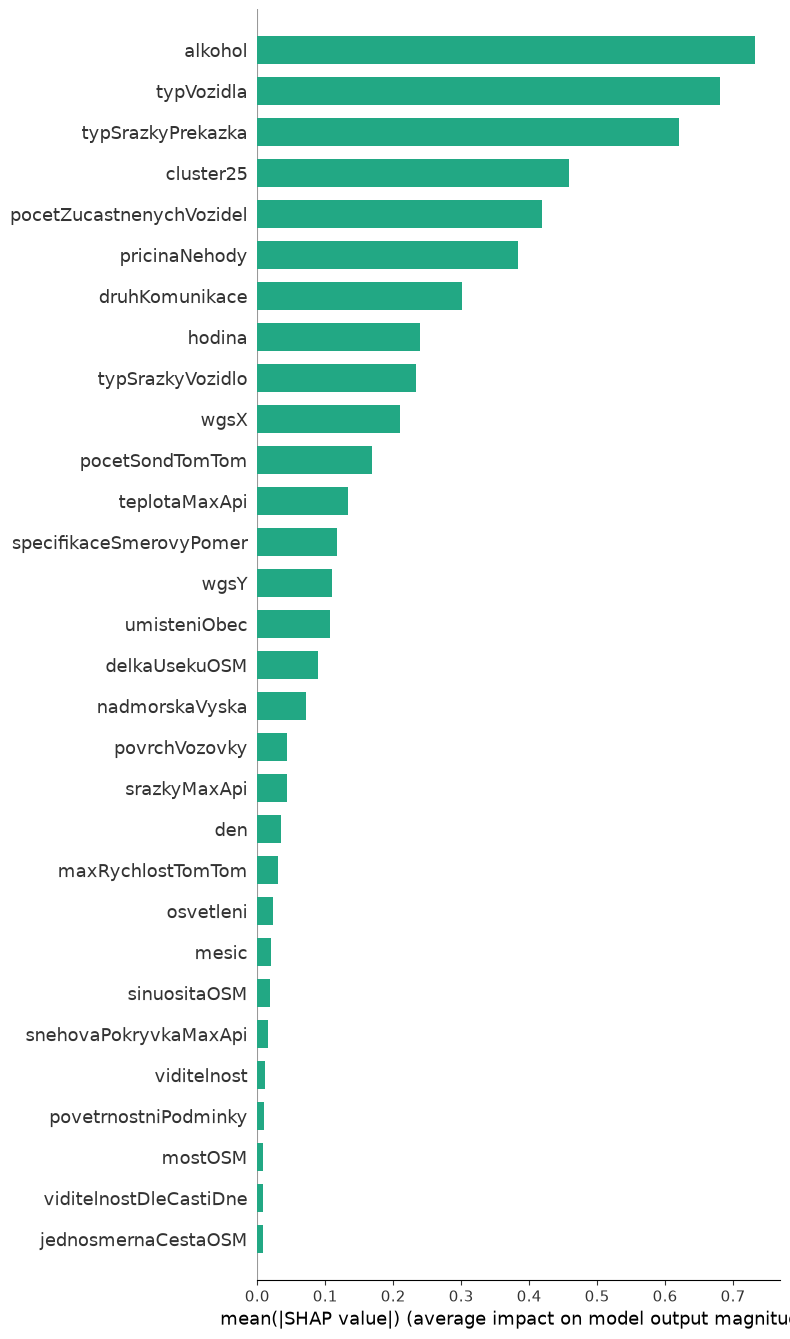

In [52]:
shap.summary_plot(
    shapValues, 
    xTrain, 
    plot_type="bar", 
    color=plt.get_cmap("viridis")(0.6), 
    show=False,
    max_display=30
)

plt.show()

# SHAP

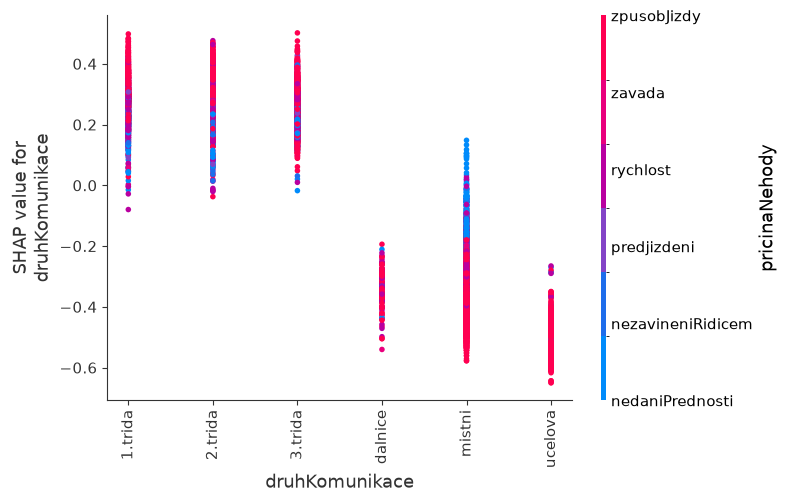

In [55]:
displayDependencePlot(shapValues,xTest,"druhKomunikace")

In [92]:
explanation=getExplanation(bestEstimator,xTest)

In [115]:
ci=getCorrectIndexes(yPred,yTest)

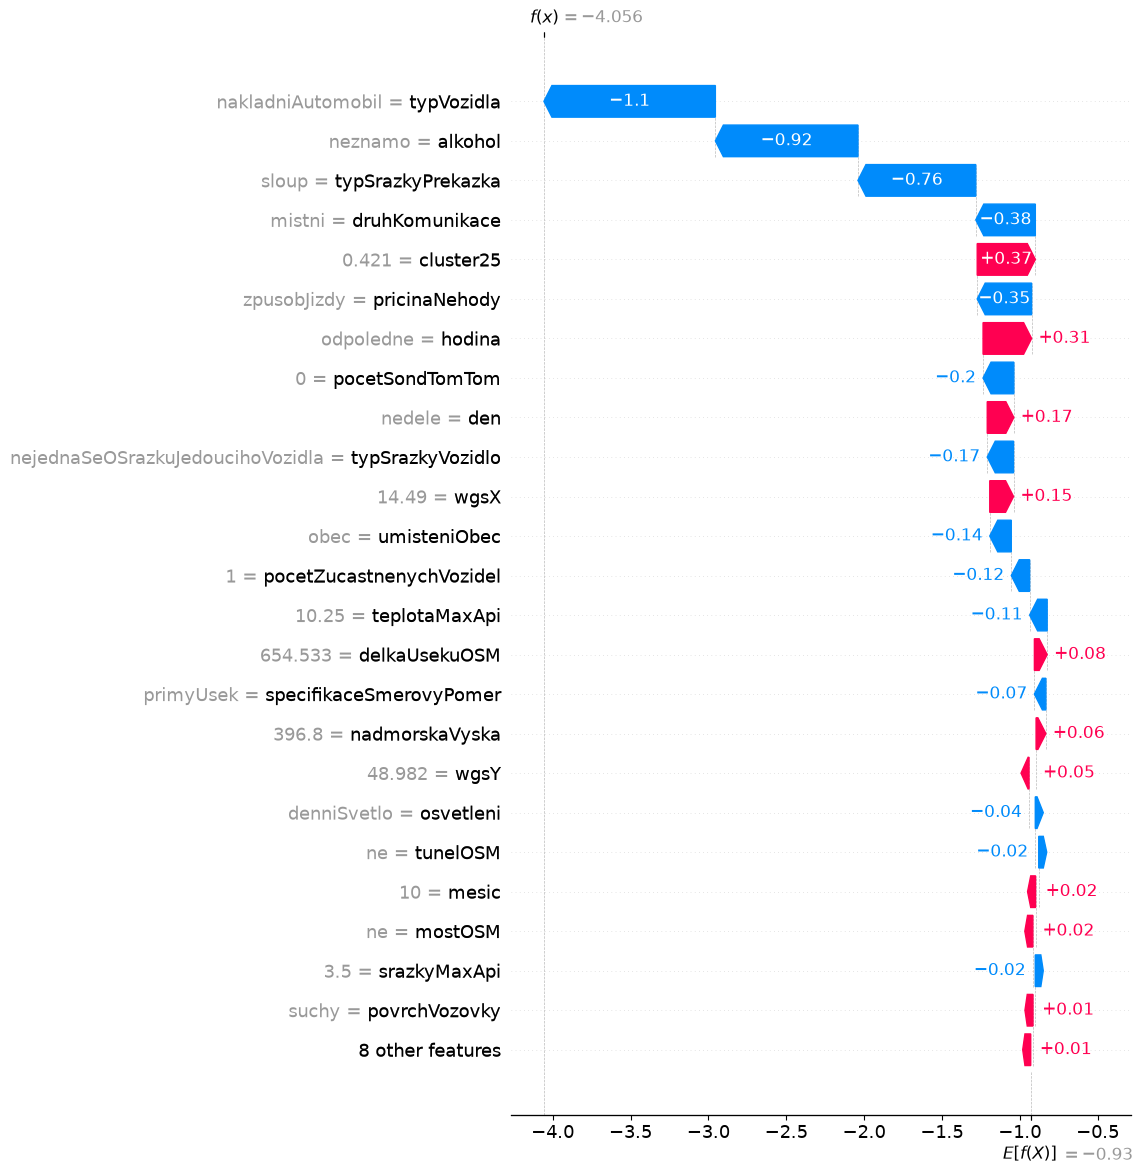

In [132]:
displayLocalValues(explanation,ci[0],25)

In [62]:
resultDf=getValuesByShapThreshold(xTest,"cluster25",1,shapValues,dfAccidents)

In [61]:
import webbrowser
import geopandas as gpd

In [63]:

gdf = gpd.GeoDataFrame(
    resultDf, 
    geometry=gpd.points_from_xy(resultDf.wgsX, resultDf.wgsY),
    crs="EPSG:4326"
)


In [64]:
m=gdf.explore(
    column='shapValue', 
    cmap='Reds',  
 tiles="CartoDB.Positron",      
    marker_kwds=dict(radius=5),
    legend=True
         
)

mapFile = "shapResult.html"
m.save(mapFile)
webbrowser.open('file://' + os.path.realpath(mapFile))

True

# Neural Network klasifikace

In [15]:
from sklearn.preprocessing import PowerTransformer
from sklearn.utils.class_weight import compute_class_weight

yeoTransformer = PowerTransformer(method='yeo-johnson', standardize=True)

In [16]:
severityMapping = {
    'pouzeHmotnaSkoda': 0,
    'lehceZavaznaNehoda': 1,
    'zavaznaNehoda': 1,
    'smrtelnaNehoda': 1
}

y=df['zavaznostNehody'].map(severityMapping)
X = df[catCols + numCols+mixCol]

X=pd.get_dummies(X,columns=catCols)

xTrain, xTest, yTrain, yTest = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

xTrain[numCols] = yeoTransformer.fit_transform(xTrain[numCols])
xTest[numCols] = yeoTransformer.transform(xTest[numCols])


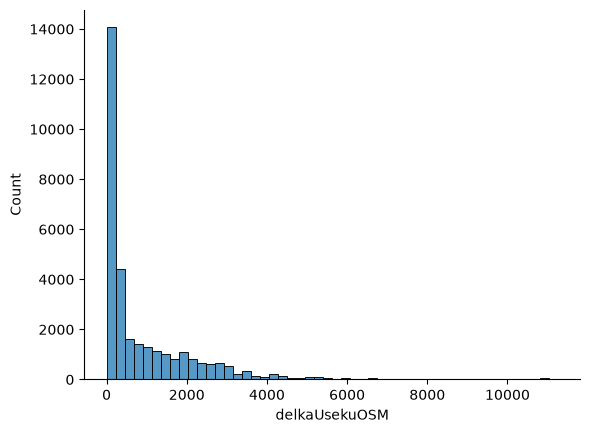

In [ ]:
sns.histplot(
    data=xTrain, 
    x='delkaUsekuOSM', 
    bins=50    
)

sns.despine()

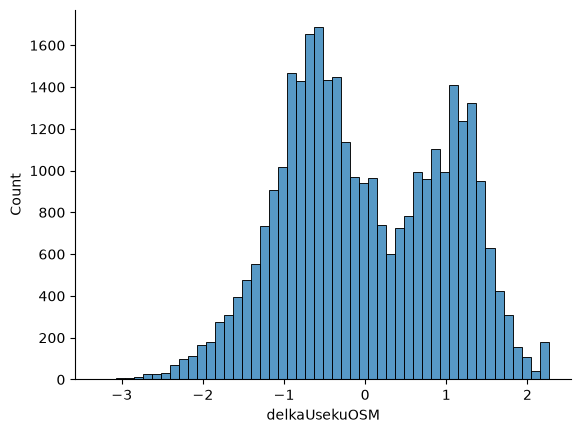

In [ ]:
sns.histplot(
    data=xTrain, 
    x='delkaUsekuOSM',           
    bins=50    
)
sns.despine()

In [17]:
weights= compute_sample_weight(class_weight='balanced', y=yTrain)

xTrain,xTest=performTargetEncoding(xTrain,yTrain,xTest,"cluster25")


In [18]:
def createModel(xTrain,yTrain,inputShape,outputShape,epochsNumber):

    keras.utils.set_random_seed(42)
    
    model = Sequential()  
    model.add(Dense(inputShape, input_dim=inputShape, activation='relu'))      
    model.add(Dense(10, activation='relu'))
    model.add(Dense(20, activation='relu'))
    model.add(Dense(10, activation='relu'))    
    model.add(Dense(outputShape, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

    history= model.fit(xTrain,yTrain,epochs=epochsNumber,validation_split=0.3,batch_size=20,sample_weight=weights)
    _, accuracy = model.evaluate(xTrain, yTrain)

    print(history.history)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('model accuracy')
    plt.ylabel('accuracy')
    plt.xlabel('epoch')
    plt.legend(['train', 'test'], loc='upper left')
    plt.show()
   
    print('Accuracy: %.2f' % (accuracy*100)) 

    return model


In [19]:
xTrainNS=np.asarray(xTrain).astype(np.float32)
yTrainNS=pd.get_dummies(yTrain) 
yTrainNS=np.asarray(yTrainNS).astype(np.float32)

xTestNS=np.asarray(xTest).astype(np.float32)
yTestNS=np.asarray(yTest).astype(np.float32)

Epoch 1/4
  15/1128 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6200 - loss: 0.6950  

c:\Users\dkuch\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1128/1128 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7951 - loss: 0.4332 - val_accuracy: 0.8216 - val_loss: 0.3763
Epoch 2/4
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8261 - loss: 0.3730 - val_accuracy: 0.8284 - val_loss: 0.3691
Epoch 3/4
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8313 - loss: 0.3593 - val_accuracy: 0.8131 - val_loss: 0.3749
Epoch 4/4
1128/1128 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8380 - loss: 0.3494 - val_accuracy: 0.8305 - val_loss: 0.3636
1007/1007 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8403 - loss: 0.3507
{'accuracy': [0.7950935959815979, 0.8261467218399048, 0.8312926888465881, 0.8380356431007385], 'loss': [0.4331567585468292, 0.3729514479637146, 0.35929861664772034, 0.34938448667526245], 'val_accuracy': [0.82156902551651, 0.8283998966217041, 0.8130821585655212, 0.8304699063301086], 'val_loss': [0.3763309121131897, 0.369084894657135, 0.37492406368255615, 0.3636094033718109]}


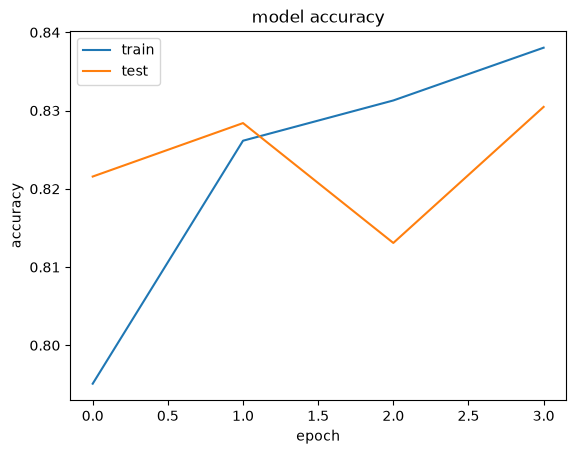

Accuracy: 84.03


In [20]:
model=createModel(xTrainNS,yTrainNS,112,2,4)

In [217]:
model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_65 (Dense)                │ (None, 112)            │        12,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_66 (Dense)                │ (None, 10)             │         1,130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_67 (Dense)                │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_68 (Dense)                │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_69 (Dense)                │ (None, 2)              │            22 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,716 (166.86 KB)

 Trainable params: 14,238 (55.62 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 28,478 (111.24 KB)

In [21]:
predictions=model.predict(xTestNS)
roundPred = np.argmax(predictions, axis=1)


252/252 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


              precision    recall  f1-score   support

         0.0       0.90      0.81      0.85      4939
         1.0       0.74      0.86      0.79      3113

    accuracy                           0.83      8052
   macro avg       0.82      0.83      0.82      8052
weighted avg       0.84      0.83      0.83      8052



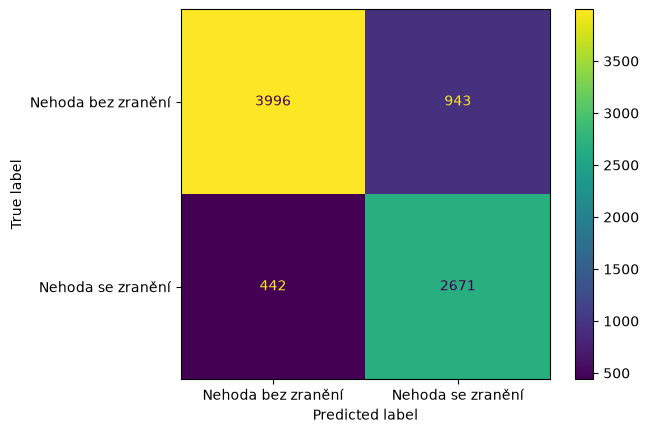

In [22]:


cm = confusion_matrix(yTestNS, roundPred)
#ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=originalY.columns).plot()
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Nehoda bez zranění","Nehoda se zranění"]).plot()

print(classification_report(yTestNS, roundPred))

# Pocet nehod

In [49]:
import pandas as pd
dfAccidents['datum'] = pd.to_datetime(dfAccidents['datum'])

cols = ['usekStartOSM', 'usekKonecOSM'] 

segmentsInfo=(dfAccidents
                       .groupby(['usekStartOSM', 'usekKonecOSM'])
                       .agg({'maxRychlostTomTom': 'max', 'delkaUsekuOSM': 'max',"pocetSondTomTom":"max","sinuositaOSM":"max"}) 
                       .reset_index())

segments = dfAccidents[cols].drop_duplicates()

months = pd.date_range(start="2016-01-01", end="2025-12-31", freq="YE")

tab = segments.merge(pd.DataFrame({'datum': months}), how='cross')
tabIndex= pd.MultiIndex.from_frame(tab)

r = (dfAccidents.groupby(cols + [pd.Grouper(key="datum", freq="YE")])
              .size()
              .reindex(tabIndex, fill_value=0)
              .reset_index(name='pocetNehod'))



In [50]:
dfResult = r.merge(
    segmentsInfo, 
    on=['usekStartOSM', 'usekKonecOSM'], 
    how='left'
)

In [51]:
dfResult['rok'] =dfResult['datum'].dt.year

dfResult=dfResult.dropna()

In [ ]:
dfResult.to_csv("pocetNehod.csv",index=False,sep=";")

# Import dat - Pocet nehod

In [46]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score,mean_poisson_deviance
import matplotlib.pyplot as plt

df = pd.read_csv("pocetNehod.csv",sep=';')

In [47]:
import numpy as np
import statsmodels.formula.api as smf
from statsmodels.discrete.count_model import ZeroInflatedPoisson
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf

<Axes: xlabel='pocetNehod', ylabel='count'>

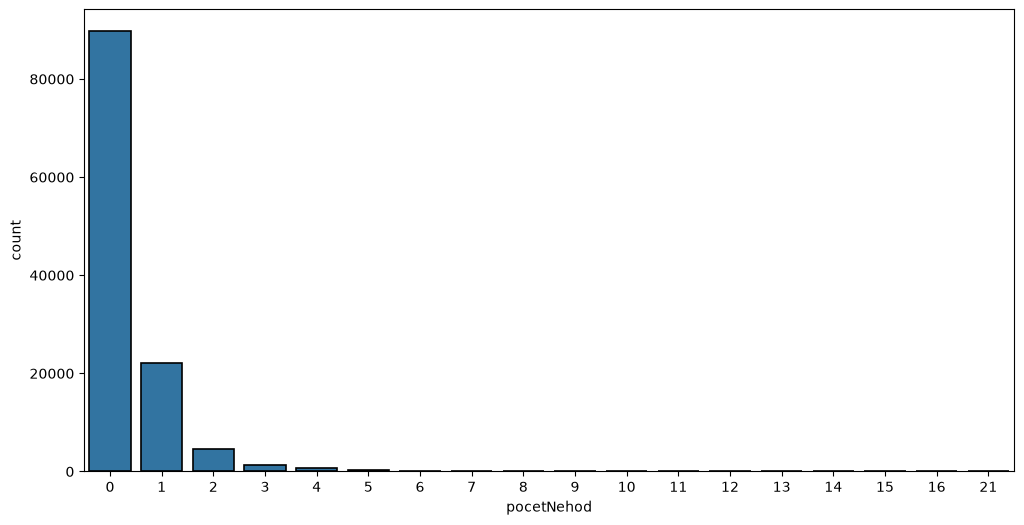

In [48]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df,x="pocetNehod",
    edgecolor='black', 
    linewidth=1.2)

# ZIP

In [42]:
trainDf, testDf = train_test_split(df, test_size=0.2, random_state=42)
scaler = StandardScaler()

trainDf[['maxRychlostTomTom', 'delkaUsekuOSM', 'pocetSondTomTom', 'sinuositaOSM']] = scaler.fit_transform(
    trainDf[['maxRychlostTomTom', 'delkaUsekuOSM', 'pocetSondTomTom', 'sinuositaOSM']]
)

testDf[['maxRychlostTomTom', 'delkaUsekuOSM', 'pocetSondTomTom', 'sinuositaOSM']] = scaler.transform(
   testDf[['maxRychlostTomTom', 'delkaUsekuOSM', 'pocetSondTomTom', 'sinuositaOSM']]
)


In [43]:

formula = 'pocetNehod ~ pocetSondTomTom + delkaUsekuOSM + sinuositaOSM + maxRychlostTomTom'

zip_model = ZeroInflatedPoisson.from_formula(formula, data=trainDf, inflation='logit')
results = zip_model.fit()

yPred= results.predict(exog=testDf)

yTest = testDf['pocetNehod']

Optimization terminated successfully.
         Current function value: 0.747934
         Iterations: 18
         Function evaluations: 19
         Gradient evaluations: 19


In [44]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                     ZeroInflatedPoisson Regression Results                    
===============================================================================
Dep. Variable:              pocetNehod   No. Observations:                95176
Model:             ZeroInflatedPoisson   Df Residuals:                    95171
Method:                            MLE   Df Model:                            4
Date:                  út, 20 říj 2026   Pseudo R-squ.:                 0.04178
Time:                         12:23:19   Log-Likelihood:                -71185.
converged:                        True   LL-Null:                       -74289.
Covariance Type:             nonrobust   LLR p-value:                     0.000
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
inflate_const        -0.3979      0.014    -28.525      0.000      -0.425      -0.371
Intercept            -0.6312      0.006    -99.398      0.000      -0.644      -0.619
pocetSondTomTom       0.1952      0.004     54.508      0.000       0.188       0.202
delkaUsekuOSM         0.1262      0.004     29.297      0.000       0.118       0.135
sinuositaOSM          0.0791      0.005     14.991      0.000       0.069       0.089
maxRychlostTomTom     0.0458      0.007      6.499      0.000       0.032       0.060
=====================================================================================
"""

In [45]:
print(f"MAE: {mean_absolute_error(yTest, yPred):.2f}")
print(f"RMSE: {root_mean_squared_error(yTest, yPred):.2f}")
print(f"R2 Score: {r2_score(yTest, yPred):.2f}")
print(f"MPD (Poisson deviance): {mean_poisson_deviance(yTest, yPred):.4f}")

MAE: 0.50
RMSE: 0.76
R2 Score: 0.05
MPD (Poisson deviance): 0.9960


# Poisson

In [58]:

formula = 'pocetNehod ~ pocetSondTomTom + delkaUsekuOSM + sinuositaOSM + maxRychlostTomTom'

poisson_model = smf.poisson(formula, data=trainDf)

results = poisson_model.fit()

yPred = results.predict(exog=testDf)


yTest = testDf['pocetNehod']

Optimization terminated successfully.
         Current function value: 0.762327
         Iterations 12


In [59]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                          Poisson Regression Results                          
==============================================================================
Dep. Variable:             pocetNehod   No. Observations:                95176
Model:                        Poisson   Df Residuals:                    95171
Method:                           MLE   Df Model:                            4
Date:                 čt, 15 říj 2026   Pseudo R-squ.:                 0.05857
Time:                        18:15:59   Log-Likelihood:                -72555.
converged:                       True   LL-Null:                       -77069.
Covariance Type:            nonrobust   LLR p-value:                     0.000
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -1.1421      0.006   -196.690      0.000      -1.153      -1.131
pocetSondTomTom       0.2132      0.003     66.518      0.000       0.207       0.219
delkaUsekuOSM         0.1637      0.004     42.649      0.000       0.156       0.171
sinuositaOSM          0.0544      0.005     11.772      0.000       0.045       0.063
maxRychlostTomTom     0.0360      0.006      5.795      0.000       0.024       0.048
=====================================================================================
"""

In [60]:
print(f"MAE: {mean_absolute_error(yTest, yPred):.2f}")
print(f"RMSE: {root_mean_squared_error(yTest, yPred):.2f}")
print(f"R2 Score: {r2_score(yTest, yPred):.2f}")
print(f"MPD (Poisson deviance): {mean_poisson_deviance(yTest, yPred):.4f}")

MAE: 0.50
RMSE: 0.80
R2 Score: -0.05
MPD (Poisson deviance): 0.9947


# XGB regresor

In [50]:
df = pd.read_csv("pocetNehod.csv",sep=';')

In [52]:
#df=df[df.druhKomunikace=="ucelova"]

X = df.drop(columns=['pocetNehod','usekStartOSM', 'usekKonecOSM',"datum","rok"])
y = df['pocetNehod']

xTrain, xTest, yTrain, yTest = train_test_split(X, y, test_size=0.2, random_state=42)

In [53]:

model = xgb.XGBRegressor(
  objective='count:poisson',
  enable_categorical=True,
    random_state=42,
)

gridParams = {  
    'max_depth': [4,6,8,10,12],
    'learning_rate': [0.05, 0.1],
    'n_estimators': [100,200,300,400,500,600,800,1000]
}

gridSearch = GridSearchCV(
    estimator=model, 
    param_grid=gridParams, 
    cv=3, 
    scoring="neg_mean_poisson_deviance",
    verbose=2, 
    n_jobs=-1
)

gridSearch.fit(xTrain, yTrain)

bestEstimator = gridSearch.best_estimator_


Fitting 3 folds for each of 80 candidates, totalling 240 fits


In [54]:
bestEstimator

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'count:poisson'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor

# CatBoost regressor

In [58]:
from catboost import CatBoostRegressor

gridParams = {   
    'iterations': [100, 200,300,400,500,600,800,1000],
    'depth': [4, 6,8,10,12],
    'learning_rate': [0.05, 0.1]
}


model = CatBoostRegressor(loss_function="Poisson",random_state=42)

gridSearch = GridSearchCV(
    estimator=model, 
    param_grid=gridParams, 
    cv=3, 
    scoring="neg_mean_poisson_deviance",
    verbose=2, 
    n_jobs=-1
)

gridSearch.fit(xTrain,yTrain)

bestEstimator = gridSearch.best_estimator_


Fitting 3 folds for each of 80 candidates, totalling 240 fits
0:	learn: 0.9526338	total: 71.5ms	remaining: 1m 11s
1:	learn: 0.9123291	total: 142ms	remaining: 1m 10s
2:	learn: 0.8767146	total: 212ms	remaining: 1m 10s
3:	learn: 0.8466693	total: 283ms	remaining: 1m 10s
4:	learn: 0.8196181	total: 355ms	remaining: 1m 10s
5:	learn: 0.7958838	total: 424ms	remaining: 1m 10s
6:	learn: 0.7752138	total: 501ms	remaining: 1m 11s
7:	learn: 0.7570480	total: 576ms	remaining: 1m 11s
8:	learn: 0.7413081	total: 650ms	remaining: 1m 11s
9:	learn: 0.7279039	total: 718ms	remaining: 1m 11s
10:	learn: 0.7158001	total: 785ms	remaining: 1m 10s
11:	learn: 0.7054434	total: 851ms	remaining: 1m 10s
12:	learn: 0.6958450	total: 924ms	remaining: 1m 10s
13:	learn: 0.6872450	total: 997ms	remaining: 1m 10s
14:	learn: 0.6796041	total: 1.07s	remaining: 1m 10s
15:	learn: 0.6726688	total: 1.14s	remaining: 1m 10s
16:	learn: 0.6662748	total: 1.21s	remaining: 1m 9s
17:	learn: 0.6603989	total: 1.29s	remaining: 1m 10s
18:	learn: 0

In [59]:
bestEstimator

CatBoostRegressor(depth=12, iterations=1000, learning_rate=0.05, loss_function='Poisson', random_state=42)

In [278]:
shapValues=getShapValues(bestEstimator,xTest)

C:\Users\dkuch\AppData\Local\Temp\ipykernel_19804\402781686.py:80: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shapValues, xTest, max_display=maxCols, show=False)


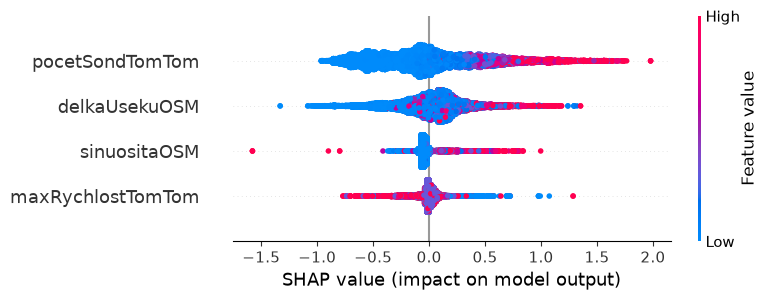

In [279]:
displayNumericSummaryPlot(shapValues,xTest,30)

# Random Forest regresor

In [67]:
from sklearn.ensemble import RandomForestRegressor

gridParams = {   
    'n_estimators': [100, 200, 300, 400,600,800,1000,1200],
    'max_depth': [4, 6,8,10,12,14,16]
}

model = RandomForestRegressor(
    criterion="poisson",
    random_state=42
)

gridSearch = GridSearchCV(
    estimator=model, 
    param_grid=gridParams, 
    cv=3, 
    scoring="neg_mean_poisson_deviance",
    verbose=2, 
    n_jobs=-1
)

gridSearch.fit(xTrain, yTrain)

bestEstimator = gridSearch.best_estimator_

Fitting 3 folds for each of 56 candidates, totalling 168 fits


In [69]:
bestEstimator

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'poisson'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the i

# Neural network regrese


In [63]:
from sklearn.preprocessing import PowerTransformer
from sklearn.utils.class_weight import compute_class_weight

yeoTransformer = PowerTransformer(method='yeo-johnson', standardize=True)

In [73]:
def createModel(xTrain,yTrain,inputShape,outputShape,epochsNumber):
    keras.utils.set_random_seed(42)

    model = Sequential()  
    model.add(Dense(inputShape, input_dim=inputShape, activation='relu'))      
    model.add(Dense(15, activation='relu'))
    model.add(Dense(30, activation='relu'))
    model.add(Dense(15, activation='relu'))    
    model.add(Dense(outputShape, activation='exponential'))
    #model.add(Dense(outputShape))
    model.compile(loss='poisson', optimizer='adam', metrics=['mean_squared_error'])

    history= model.fit(xTrain,yTrain,epochs=epochsNumber,validation_split=0.3, batch_size=50)
    _, mse = model.evaluate(xTrain, yTrain)

    print(history.history)

    plt.figure(figsize=(10, 6))
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Poisson Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper right')
    plt.show()

    return model

In [74]:
xTrain, xTest, yTrain, yTest = train_test_split(X, y, test_size=0.2, random_state=42)

xTrain[['maxRychlostTomTom','delkaUsekuOSM', 'pocetSondTomTom',"sinuositaOSM"]]=yeoTransformer.fit_transform(xTrain[['maxRychlostTomTom','delkaUsekuOSM', 'pocetSondTomTom',"sinuositaOSM"]])
xTest[['maxRychlostTomTom','delkaUsekuOSM', 'pocetSondTomTom',"sinuositaOSM"]]=yeoTransformer.transform(xTest[['maxRychlostTomTom','delkaUsekuOSM', 'pocetSondTomTom',"sinuositaOSM"]])



In [75]:
xTrainNS=np.asarray(xTrain).astype(np.float32) 
yTrainNS=np.asarray(yTrain).astype(np.float32)

Epoch 1/10
  14/1333 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.9196 - mean_squared_error: 1.1433

  43/1333 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.8110 - mean_squared_error: 0.7388

c:\Users\dkuch\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1333/1333 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.6448 - mean_squared_error: 0.5134 - val_loss: 0.6292 - val_mean_squared_error: 0.5315
Epoch 2/10
1333/1333 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.6196 - mean_squared_error: 0.4813 - val_loss: 0.6257 - val_mean_squared_error: 0.5194
Epoch 3/10
1333/1333 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.6176 - mean_squared_error: 0.4795 - val_loss: 0.6264 - val_mean_squared_error: 0.5238
Epoch 4/10
1333/1333 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.6163 - mean_squared_error: 0.4773 - val_loss: 0.6210 - val_mean_squared_error: 0.5136
Epoch 5/10
1333/1333 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.6154 - mean_squared_error: 0.4759 - val_loss: 0.6222 - val_mean_squared_error: 0.5174
Epoch 6/10
1333/1333 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.6152 - mean_squared_error: 0.4759 - val_loss: 0.6210 - val_mean_squared_error: 0.5144
Epoch 7/10
1333/1333 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 0.6147 - mean_squared_error: 0.4754 - val_loss: 0

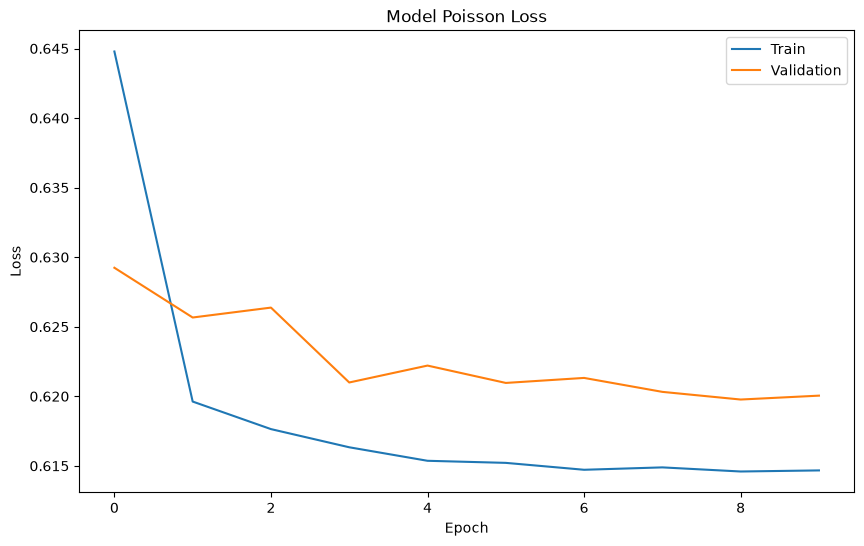

In [76]:
model=createModel(xTrainNS,yTrainNS,4,1,10)

In [246]:
model.summary()

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_85 (Dense)                │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 15)             │            75 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_87 (Dense)                │ (None, 30)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_88 (Dense)                │ (None, 15)             │           465 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_89 (Dense)                │ (None, 1)              │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,170 (12.38 KB)

 Trainable params: 1,056 (4.12 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,114 (8.26 KB)

# Confusion matrix

In [78]:
yPred = model.predict(xTest)
#yPred=bestEstimator.predict(xTest)

print(f"MAE: {mean_absolute_error(yTest, yPred):.2f}")
print(f"RMSE: {root_mean_squared_error(yTest, yPred):.2f}") 
print(f"R2 Score: {r2_score(yTest, yPred):.2f}")
print(f"MPD: {mean_poisson_deviance(yTest,yPred)}")

744/744 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
MAE: 0.45
RMSE: 0.71
R2 Score: 0.18
MPD: 0.8858535885810852


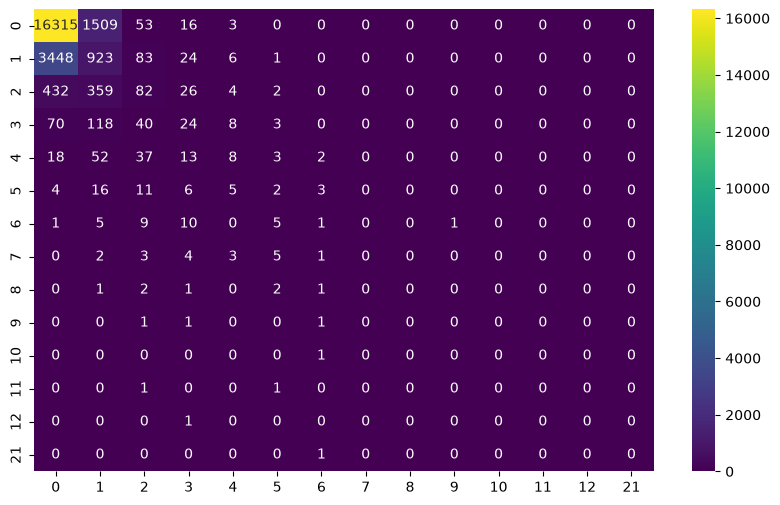

              precision    recall  f1-score   support

           0       0.80      0.91      0.85     17896
           1       0.31      0.21      0.25      4485
           2       0.25      0.09      0.13       905
           3       0.19      0.09      0.12       263
           4       0.22      0.06      0.09       133
           5       0.08      0.04      0.06        47
           6       0.09      0.03      0.05        32
           7       0.00      0.00      0.00        18
           8       0.00      0.00      0.00         7
           9       0.00      0.00      0.00         3
          10       0.00      0.00      0.00         1
          11       0.00      0.00      0.00         2
          12       0.00      0.00      0.00         1
          21       0.00      0.00      0.00         1

    accuracy                           0.73     23794
   macro avg       0.14      0.10      0.11     23794
weighted avg       0.68      0.73      0.70     23794

Accuracy: 0.73
F1 Score: 

c:\Users\dkuch\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\dkuch\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\dkuch\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [61]:

yPredRound = np.rint(yPred).astype(int)
yTestAsInt = yTest.astype(int)


cm = confusion_matrix(yTestAsInt, yPredRound)


plt.figure(figsize=(10, 6))
sns.heatmap(cm, annot=True, fmt='d',cmap='viridis', 
            xticklabels=np.unique(yTestAsInt), 
            yticklabels=np.unique(yTestAsInt))

plt.xlabel('')
plt.ylabel('')
plt.title('')
plt.show()

print(classification_report(yTestAsInt, yPredRound))


f1Score = f1_score(yTestAsInt, yPredRound, average='macro')
accuracyScore = accuracy_score(yTestAsInt, yPredRound)

print(f"Accuracy: {accuracyScore:.2f}")
print(f"F1 Score: {f1Score:.2f}")

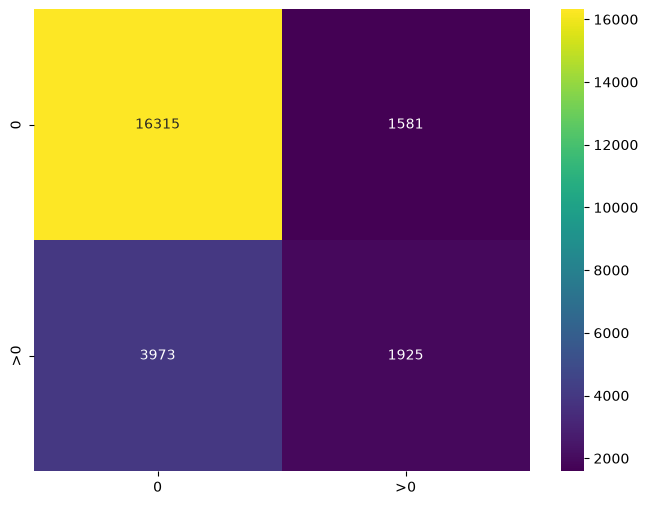

              precision    recall  f1-score   support

     pocet=0       0.80      0.91      0.85     17896
     pocet>0       0.55      0.33      0.41      5898

    accuracy                           0.77     23794
   macro avg       0.68      0.62      0.63     23794
weighted avg       0.74      0.77      0.74     23794



In [62]:
threshold = 0.5

y_test_binary = (yTest > 0).astype(int)
y_pred_binary = (yPred > threshold).astype(int) 

# 2. Vytvoření matice záměn
cm_binary = confusion_matrix(y_test_binary, y_pred_binary)

# 3. Vykreslení
plt.figure(figsize=(8, 6))
sns.heatmap(cm_binary, annot=True, fmt='d', cmap='viridis',
            xticklabels=['0', '>0'], 
            yticklabels=['0', '>0'])

plt.show()


print(classification_report(y_test_binary, y_pred_binary, target_names=['pocet=0', 'pocet>0']))